# 📌 Proyecto Final: ¿Por qué DataLatte dejó de crecer?
**Autor:** Albert · **Curso:** DataLab

Este notebook reúne todo el análisis que respalda el informe escrito. Está ordenado igual que la consigna:

1. Definir el problema
2. Explorar los datos
3. Sacar conclusiones
4. Mostrar resultados (los 7 gráficos del informe)
5. Proponer ideas
6. Aprendizaje

Al final hay una sección de **verificación** que recalcula todas las cifras citadas en el informe.

> Se trabaja con el **dataset depurado** del Módulo III (el mismo que usan los Módulos IV y V).

## 0. Carga de librerías y datos
Como en todos los Colab del curso, primero cargamos las librerías y los datos.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
import seaborn as sns

# Si el archivo está subido a Colab se usa ese; si no, se descarga del link del curso
archivo_local = 'ventas_depuradas.csv'
url_datalatte = 'https://drive.google.com/uc?export=download&id=1Y4AzhDV6pr0mYvoJK4poa3wFxl3ac09p'
datalatte = pd.read_csv(archivo_local if os.path.exists(archivo_local) else url_datalatte)
datalatte.head()

,Id cliente,Fecha,Canal,Monto,Producto,Id tienda,Id venta,Nombre,Email,Ciudad,Edad,Nombre Tienda,Tipo,Ubicacion,Fecha Apertura,Inversion_Marketing
0,2299,2024-02-14,Tienda Física,724.766010,Café Molido,Tienda Centro,22486,Cliente_1300,cliente_1300@ejemplo.com,Canelones,55.0,Tienda Centro,Tienda Física,Centro,2017-01-23,2191.0
1,2502,2023-04-25,Ecommerce,272.240000,Granos de Café,Online Local,6257,Cliente_1503,cliente_1503@ejemplo.com,Maldonado,33.0,Online Local,Ecommerce,Ubicación no registrada,2016-09-01,3866.0
2,3175,2023-11-13,Tienda Física,701.840000,Granos de Café,Tienda Centro,17164,Cliente_2176,cliente_2176@ejemplo.com,Colonia,40.0,Tienda Centro,Tienda Física,Centro,2017-01-23,3418.0
3,4893,2023-07-16,Tienda Física,596.597411,Combos Especiales,Tienda Pocitos,10650,Cliente_3894,cliente_3894@ejemplo.com,Canelones,45.0,Tienda Pocitos,Tienda Física,Centro,2017-10-04,5283.0
4,4634,2024-05-21,Tienda Física,772.971034,Accesorios de Café,Tienda Pocitos,27631,Cliente_3635,cliente_3635@ejemplo.com,Canelones,40.0,Tienda Pocitos,Tienda Física,Centro,2017-10-04,3113.0


### Chequeo rápido de calidad
Confirmamos que el dataset está limpio (lo que hicimos en el Módulo III).

In [2]:
print('Filas y columnas:', datalatte.shape)
print('Valores nulos:', datalatte.isna().sum().sum())
print('Filas duplicadas:', datalatte.duplicated().sum())
print('Montos negativos:', (datalatte['Monto'] < 0).sum())
print('Id venta negativos:', (datalatte['Id venta'] < 0).sum())

# Convertimos la fecha y creamos columnas de año, mes y semestre
datalatte['Fecha'] = pd.to_datetime(datalatte['Fecha'], format='%Y-%m-%d')
datalatte['Año'] = datalatte['Fecha'].dt.year
datalatte['Mes'] = datalatte['Fecha'].dt.to_period('M').dt.to_timestamp()
datalatte['Semestre'] = datalatte['Año'].astype(str) + '-S' + ((datalatte['Fecha'].dt.month > 6) + 1).astype(str)
print('Período:', datalatte['Fecha'].min().date(), 'a', datalatte['Fecha'].max().date())

Filas y columnas: (39948, 16)
Valores nulos: 0
Filas duplicadas: 0
Montos negativos: 0
Id venta negativos: 0
Período: 2023-01-01 a 2024-12-31


### Configuración de los gráficos
Definimos colores y formato una sola vez para que todos los gráficos sean consistentes (tip de storytelling del Módulo V: menos es más, colores con sentido).

In [3]:
C = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']   # azul, naranja, verde agua, amarillo
INK, INK2, GRID = '#0b0b0b', '#52514e', '#e4e3df'
plt.rcParams.update({'font.size': 10, 'axes.edgecolor': GRID, 'axes.labelcolor': INK2,
    'xtick.color': INK2, 'ytick.color': INK2, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'axes.titleweight': 'bold', 'axes.titlesize': 12, 'axes.titlelocation': 'left', 'figure.facecolor': 'white'})

K = FuncFormatter(lambda v, p: f'{v/1000:,.0f} k'.replace(',', '.'))   # 1.200 k en vez de 1200000
MESES = {'Jan': 'Ene', 'Apr': 'Abr'}
def formato_meses(ax):
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
    ax.xaxis.set_major_formatter(FuncFormatter(
        lambda v, p: mdates.num2date(v).strftime('%b %y').replace('Jan', 'Ene').replace('Apr', 'Abr')))
def linea_quiebre(ax):
    ax.axvline(pd.Timestamp('2024-01-16'), color=INK2, lw=1, ls=':')   # entre enero y febrero de 2024

## 1. Definir el problema
Que las ventas estén "estancadas" puede significar varias cosas. Como

**Monto vendido = cantidad de ventas × ticket promedio**,

la primera pregunta es cuál de las dos partes explica el estancamiento. Las preguntas que guían el análisis:

- ¿El estancamiento es parejo o hay un momento en que la tendencia cambia?
- ¿Cambió la cantidad de ventas o el monto de cada venta?
- ¿Se estancaron todas las tiendas y canales por igual?
- ¿Algún producto, ciudad o grupo de clientes explica la caída?
- ¿Qué relación tiene todo esto con la inversión en marketing?

## 2. Explorar los datos
### 2.1 Comparación anual: ¿qué significa "estancado"?

In [4]:
anual = datalatte.groupby('Año').agg(
    monto=('Monto', 'sum'),
    cantidad_ventas=('Monto', 'size'),
    ticket_promedio=('Monto', 'mean'),
    clientes=('Id cliente', 'nunique'))
anual['monto_millones'] = (anual['monto'] / 1e6).round(2)
print('Variación del monto 2024 vs 2023: {:.1%}'.format(anual.loc[2024, 'monto'] / anual.loc[2023, 'monto'] - 1))
print('Variación de la cantidad de ventas: {:.1%}'.format(anual.loc[2024, 'cantidad_ventas'] / anual.loc[2023, 'cantidad_ventas'] - 1))
print('Variación de clientes distintos: {:.1%}'.format(anual.loc[2024, 'clientes'] / anual.loc[2023, 'clientes'] - 1))
anual.round(1)

Variación del monto 2024 vs 2023: 1.0%
Variación de la cantidad de ventas: 0.7%
Variación de clientes distintos: -0.2%


,monto,cantidad_ventas,ticket_promedio,clientes,monto_millones
Año,,,,,
2023,11342856.5,19906,569.8,4909,11.3
2024,11461083.4,20042,571.9,4901,11.5


A nivel anual todo parece igual (+1 %). Veamos mes a mes.

In [5]:
mensual = datalatte.groupby('Mes').agg(
    monto=('Monto', 'sum'),
    cantidad_ventas=('Monto', 'size'),
    ticket_promedio=('Monto', 'mean'),
    inversion_mkt=('Inversion_Marketing', 'mean'),
    clientes=('Id cliente', 'nunique'))
mensual['tendencia_3m'] = mensual['monto'].rolling(window=3, center=True).mean()   # media móvil como en el Módulo V
mensual.round(1)

,monto,cantidad_ventas,ticket_promedio,inversion_mkt,clientes,tendencia_3m
Mes,,,,,,
2023-01-01,654985.1,1604,408.3,2859.2,1368,NaN
2023-02-01,628002.2,1463,429.3,2999.1,1238,708146.7
2023-03-01,841452.7,1818,462.8,3359.1,1526,770227.5
2023-04-01,841227.4,1685,499.2,3405.7,1439,845549.4
2023-05-01,853968.0,1666,512.6,3358.3,1413,857344.3
2023-06-01,876837.5,1564,560.6,3452.9,1319,915608.3
2023-07-01,1016019.5,1717,591.7,3839.3,1456,997345.7
2023-08-01,1099180.0,1762,623.8,4025.5,1475,1074528.0
2023-09-01,1108384.3,1720,644.4,4230.1,1455,1070677.2


In [6]:
pico = mensual['monto'].idxmax()
print('Mes con más ventas:', pico.strftime('%Y-%m'), '→ $', round(mensual.loc[pico, 'monto']))
print('Diciembre 2024 vs pico: {:.1%}'.format(mensual.loc['2024-12-01', 'monto'] / mensual.loc[pico, 'monto'] - 1))
semestral = datalatte.groupby('Semestre')['Monto'].sum()
print('\nMonto por semestre (millones):'); print((semestral / 1e6).round(2))
print('\n2º semestre 2024 vs 1º semestre 2024: {:.1%}'.format(semestral['2024-S2'] / semestral['2024-S1'] - 1))

Mes con más ventas: 2024-01 → $ 1302017
Diciembre 2024 vs pico: -32.1%

Monto por semestre (millones):
Semestre
2023-S1    4.70
2023-S2    6.65
2024-S1    6.11
2024-S2    5.35
Name: Monto, dtype: float64

2º semestre 2024 vs 1º semestre 2024: -12.5%


#### 📈 Gráfico 1. Ventas mensuales y tendencia

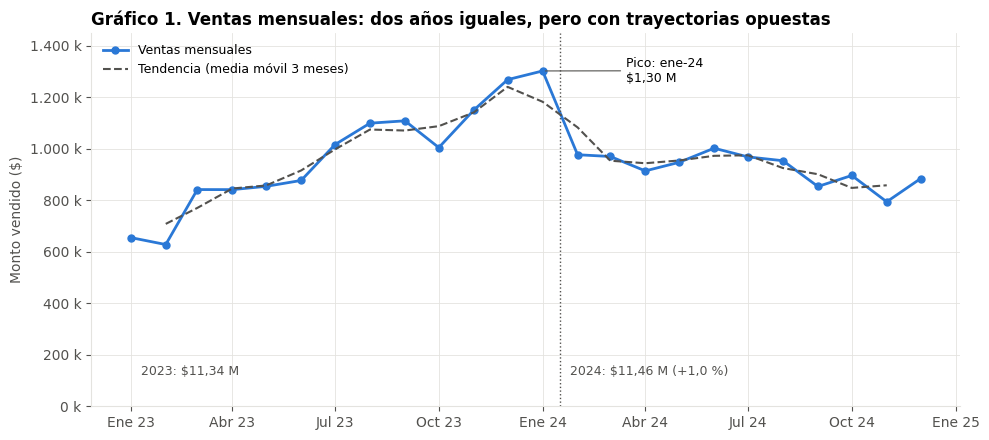

In [7]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(mensual.index, mensual['monto'], color=C[0], lw=2, marker='o', ms=5, label='Ventas mensuales')
ax.plot(mensual.index, mensual['tendencia_3m'], color=INK2, lw=1.5, ls='--', label='Tendencia (media móvil 3 meses)')
ax.yaxis.set_major_formatter(K); formato_meses(ax); linea_quiebre(ax); ax.set_ylim(0, 1450000)
ax.annotate('Pico: ene-24\n\\$1,30 M', xy=(pd.Timestamp('2024-01-01'), mensual['monto'].max()),
            xytext=(pd.Timestamp('2024-03-15'), 1260000), fontsize=9, arrowprops=dict(arrowstyle='-', color=INK2, lw=0.8))
ax.text(pd.Timestamp('2023-01-10'), 120000, '2023: \\$11,34 M', color=INK2, fontsize=9)
ax.text(pd.Timestamp('2024-01-25'), 120000, '2024: \\$11,46 M (+1,0 %)', color=INK2, fontsize=9)
ax.set_title('Gráfico 1. Ventas mensuales: dos años iguales, pero con trayectorias opuestas')
ax.set_ylabel('Monto vendido ($)'); ax.legend(frameon=False, loc='upper left', fontsize=9)
plt.tight_layout(); plt.show()

**Lectura:** 2023 creció de forma sostenida y 2024 cayó desde febrero. El total anual "plano" promedia un año de subida con otro de bajada.

### 2.2 ¿Menos ventas o ventas más chicas?

In [8]:
print('Promedio de ventas por mes: {:.0f}  (mínimo {}, máximo {})'.format(
    mensual['cantidad_ventas'].mean(), mensual['cantidad_ventas'].min(), mensual['cantidad_ventas'].max()))

clientes_2023 = set(datalatte.loc[datalatte['Año'] == 2023, 'Id cliente'])
clientes_2024 = set(datalatte.loc[datalatte['Año'] == 2024, 'Id cliente'])
ambos = clientes_2023 & clientes_2024
print('Clientes que compraron en ambos años: {} ({:.0%} de los clientes de 2023)'.format(len(ambos), len(ambos) / len(clientes_2023)))

print('\nTicket promedio en meses clave:')
print(mensual.loc[['2023-01-01', '2023-12-01', '2024-01-01', '2024-12-01'], 'ticket_promedio'].round(0))

Promedio de ventas por mes: 1664  (mínimo 1463, máximo 1859)
Clientes que compraron en ambos años: 4811 (98% de los clientes de 2023)

Ticket promedio en meses clave:
Mes
2023-01-01    408.0
2023-12-01    735.0
2024-01-01    700.0
2024-12-01    513.0
Name: ticket_promedio, dtype: float64


#### 📈 Gráfico 2. Cantidad de ventas vs ticket promedio

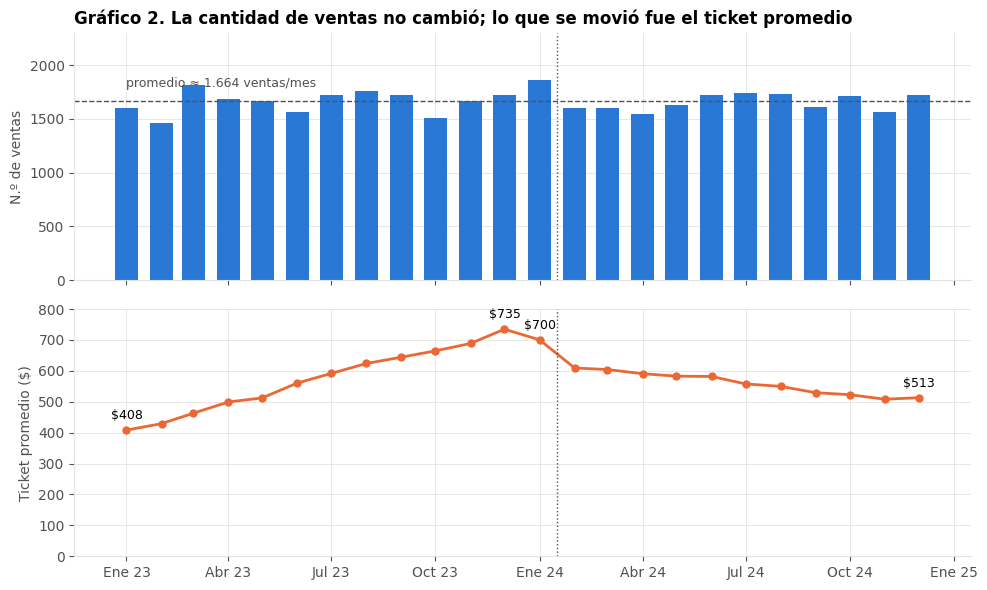

In [9]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
a1.bar(mensual.index, mensual['cantidad_ventas'], width=20, color=C[0]); a1.set_ylim(0, 2300)
a1.axhline(mensual['cantidad_ventas'].mean(), color=INK2, lw=1, ls='--')
a1.text(mensual.index[0], mensual['cantidad_ventas'].mean() + 130, 'promedio ≈ 1.664 ventas/mes', color=INK2, fontsize=9)
a1.set_ylabel('N.º de ventas')
a1.set_title('Gráfico 2. La cantidad de ventas no cambió; lo que se movió fue el ticket promedio')
a2.plot(mensual.index, mensual['ticket_promedio'], color=C[1], lw=2, marker='o', ms=5)
a2.set_ylabel('Ticket promedio ($)'); a2.set_ylim(0, 800)
for x in ['2023-01-01', '2023-12-01', '2024-01-01', '2024-12-01']:
    v = mensual.loc[x, 'ticket_promedio']
    a2.annotate(f'\\${v:.0f}', (pd.Timestamp(x), v), textcoords='offset points', xytext=(0, 8), ha='center', fontsize=9)
formato_meses(a2); linea_quiebre(a1); linea_quiebre(a2)
plt.tight_layout(); plt.show()

**Lectura:** se venden ~1.660 veces por mes en los dos años y el 98 % de los clientes se repite. El problema es que **cada venta deja menos dinero**.

### 2.3 ¿Dónde cae el ticket? Análisis por tienda

In [10]:
por_tienda = datalatte.pivot_table(index='Nombre Tienda', columns='Año', values='Monto', aggfunc=['sum', 'size', 'mean'])
por_tienda['variacion_%'] = ((por_tienda[('sum', 2024)] / por_tienda[('sum', 2023)] - 1) * 100).round(1)
por_tienda.round(1)

sum             size         mean        variacion_%
Año                  2023       2024  2023  2024   2023   2024            
Nombre Tienda                                                             
Online Global   2262255.2  1171602.2  4994  4926  453.0  237.8       -48.2
Online Local    1941683.5  2201664.0  4913  5018  395.2  438.8        13.4
Tienda Centro   3533147.2  4007681.6  4987  5017  708.5  798.8        13.4
Tienda Pocitos  3605770.6  4080135.6  5012  5081  719.4  803.0        13.2

In [11]:
orden = ['Tienda Pocitos', 'Tienda Centro', 'Online Local', 'Online Global']
ventas_tienda = datalatte.pivot_table(index='Mes', columns='Nombre Tienda', values='Monto', aggfunc='sum')
ticket_tienda = datalatte.pivot_table(index='Mes', columns='Nombre Tienda', values='Monto', aggfunc='mean')
cant_tienda = datalatte.pivot_table(index='Mes', columns='Nombre Tienda', values='Monto', aggfunc='size')

og_ene, og_feb = ticket_tienda.loc['2024-01-01', 'Online Global'], ticket_tienda.loc['2024-02-01', 'Online Global']
print('Online Global - ticket enero 2024: ${:.0f} → febrero 2024: ${:.0f} ({:.0%})'.format(og_ene, og_feb, og_feb / og_ene - 1))
print('Online Global - monto enero → febrero 2024: {:.0%}'.format(
    ventas_tienda.loc['2024-02-01', 'Online Global'] / ventas_tienda.loc['2024-01-01', 'Online Global'] - 1))
print('Online Global - ventas por mes: entre {} y {}'.format(cant_tienda['Online Global'].min(), cant_tienda['Online Global'].max()))
print('Tienda Centro - ticket dic 2023: ${:.0f} → dic 2024: ${:.0f}'.format(
    ticket_tienda.loc['2023-12-01', 'Tienda Centro'], ticket_tienda.loc['2024-12-01', 'Tienda Centro']))

Online Global - ticket enero 2024: $553 → febrero 2024: $217 (-61%)
Online Global - monto enero → febrero 2024: -66%
Online Global - ventas por mes: entre 370 y 471
Tienda Centro - ticket dic 2023: $922 → dic 2024: $726


#### 📈 Gráfico 3. Ventas mensuales por tienda

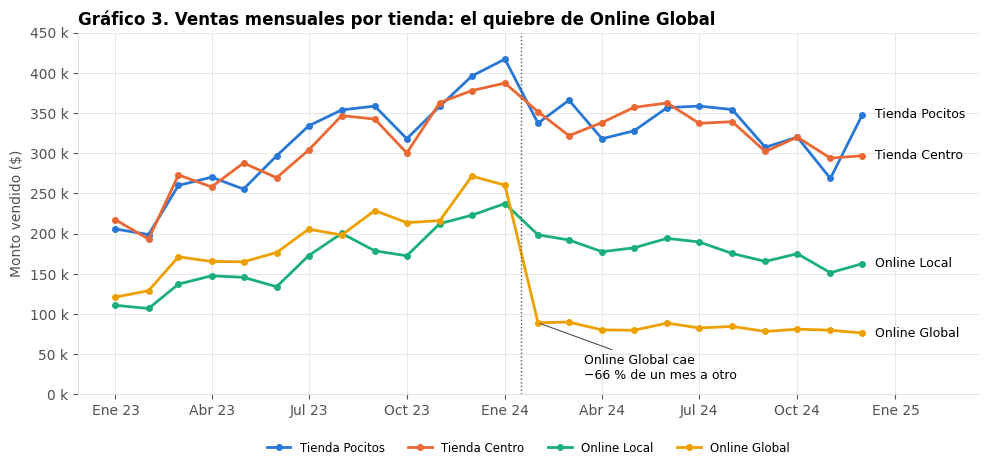

In [12]:
fig, ax = plt.subplots(figsize=(10, 4.8))
for i, t in enumerate(orden):
    ax.plot(ventas_tienda.index, ventas_tienda[t], color=C[i], lw=2, marker='o', ms=4, label=t)
    ax.text(ventas_tienda.index[-1] + pd.Timedelta(days=12), ventas_tienda[t].iloc[-1], t, fontsize=9, va='center')
ax.yaxis.set_major_formatter(K); formato_meses(ax); linea_quiebre(ax)
ax.set_xlim(right=pd.Timestamp('2025-03-20')); ax.set_ylim(0, 450000)
ax.annotate('Online Global cae\n−66 % de un mes a otro', xy=(pd.Timestamp('2024-02-01'), ventas_tienda.loc['2024-02-01', 'Online Global']),
            xytext=(pd.Timestamp('2024-03-15'), 20000), fontsize=9, arrowprops=dict(arrowstyle='-', color=INK2, lw=0.8))
ax.set_title('Gráfico 3. Ventas mensuales por tienda: el quiebre de Online Global'); ax.set_ylabel('Monto vendido ($)')
ax.legend(frameon=False, ncol=4, loc='upper center', bbox_to_anchor=(0.5, -0.1), fontsize=8.5)
plt.tight_layout(); plt.show()

#### 📈 Gráfico 4. Ticket promedio por tienda

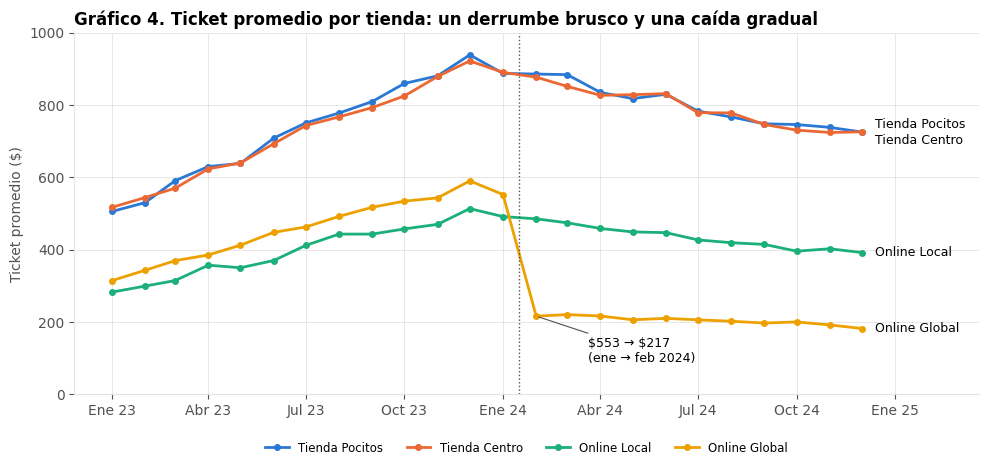

In [13]:
fig, ax = plt.subplots(figsize=(10, 4.8))
for i, t in enumerate(orden):
    ax.plot(ticket_tienda.index, ticket_tienda[t], color=C[i], lw=2, marker='o', ms=4, label=t)
    ajuste = 22 if t == 'Tienda Pocitos' else (-22 if t == 'Tienda Centro' else 0)
    ax.text(ticket_tienda.index[-1] + pd.Timedelta(days=12), ticket_tienda[t].iloc[-1] + ajuste, t, fontsize=9, va='center')
formato_meses(ax); linea_quiebre(ax); ax.set_xlim(right=pd.Timestamp('2025-03-20')); ax.set_ylim(0, 1000)
ax.annotate('\\$553 → \\$217\n(ene → feb 2024)', xy=(pd.Timestamp('2024-02-01'), og_feb),
            xytext=(pd.Timestamp('2024-03-20'), 90), fontsize=9, arrowprops=dict(arrowstyle='-', color=INK2, lw=0.8))
ax.set_title('Gráfico 4. Ticket promedio por tienda: un derrumbe brusco y una caída gradual'); ax.set_ylabel('Ticket promedio ($)')
ax.legend(frameon=False, ncol=4, loc='upper center', bbox_to_anchor=(0.5, -0.1), fontsize=8.5)
plt.tight_layout(); plt.show()

#### ¿La caída de Online Global depende de algún producto o ciudad?

In [14]:
online_global = datalatte[datalatte['Nombre Tienda'] == 'Online Global'].copy()
online_global['Periodo'] = np.where(online_global['Fecha'] >= '2024-02-01', 'Desde feb-24', 'Hasta ene-24')
print('Ticket promedio de Online Global por producto:')
display(online_global.pivot_table(index='Producto', columns='Periodo', values='Monto', aggfunc='mean').round(0))
print('Ticket promedio de Online Global por ciudad:')
display(online_global.pivot_table(index='Ciudad', columns='Periodo', values='Monto', aggfunc='mean').round(0))

Ticket promedio de Online Global por producto:


Periodo,Desde feb-24,Hasta ene-24
Producto,,
Accesorios de Café,207.0,458.0
Café Molido,205.0,456.0
Combos Especiales,202.0,467.0
Granos de Café,204.0,467.0
Producto no registrado,214.0,453.0


Ticket promedio de Online Global por ciudad:


Periodo,Desde feb-24,Hasta ene-24
Ciudad,,
Canelones,205.0,463.0
Colonia,202.0,467.0
Maldonado,205.0,455.0
Montevideo,206.0,461.0


**Lectura:** la caída es igual en todos los productos y ciudades (de ~\$460 a ~\$205). Un cambio tan parejo y brusco apunta a un evento puntual (precios, promoción, moneda o error de carga), no a un cambio de hábitos.

In [15]:
por_canal = datalatte.pivot_table(index='Canal', columns='Año', values='Monto', aggfunc='sum')
por_canal['variacion_%'] = ((por_canal[2024] / por_canal[2023] - 1) * 100).round(1)
print('Por canal:'); display(por_canal.round(0))
fisica = datalatte[datalatte['Canal'] == 'Tienda Física'].groupby('Semestre')['Monto'].sum()
print('Tienda Física por semestre (millones):'); print((fisica / 1e6).round(2))

Por canal:


Año,2023,2024,variacion_%
Canal,,,
Canal no registrado,53586.0,59605.0,11.0
Ecommerce,4184286.0,3351990.0,-20.0
Tienda Física,7104984.0,8049489.0,13.0


Tienda Física por semestre (millones):
Semestre
2023-S1    2.97
2023-S2    4.13
2024-S1    4.22
2024-S2    3.83
Name: Monto, dtype: float64


### 2.4 La relación con el marketing

In [16]:
r_mensual = mensual['monto'].corr(mensual['inversion_mkt'])
r_venta = datalatte['Monto'].corr(datalatte['Inversion_Marketing'])
sin_og = datalatte[datalatte['Nombre Tienda'] != 'Online Global'].groupby('Mes').agg(
    monto=('Monto', 'sum'), mkt=('Inversion_Marketing', 'mean'))
suma_mkt = datalatte.groupby('Mes')['Inversion_Marketing'].sum()
print(f'Correlación venta por venta (Módulo IV): {r_venta:.2f}')
print(f'Correlación mes a mes: {r_mensual:.2f}')
print(f'Correlación mes a mes sin Online Global: {sin_og["monto"].corr(sin_og["mkt"]):.2f}')
print(f'Correlación mes a mes usando la SUMA de inversión (Módulo V): {mensual["monto"].corr(suma_mkt):.2f}')
print('\nInversión promedio mensual: mínimo {:.0f} ({}), máximo {:.0f} ({}), últimos 6 meses ≈ {:.0f}'.format(
    mensual['inversion_mkt'].min(), mensual['inversion_mkt'].idxmin().strftime('%Y-%m'),
    mensual['inversion_mkt'].max(), mensual['inversion_mkt'].idxmax().strftime('%Y-%m'),
    mensual['inversion_mkt'].iloc[-6:].mean()))

Correlación venta por venta (Módulo IV): 0.29
Correlación mes a mes: 0.97
Correlación mes a mes sin Online Global: 0.88
Correlación mes a mes usando la SUMA de inversión (Módulo V): 0.95

Inversión promedio mensual: mínimo 2859 (2023-01), máximo 4559 (2024-01), últimos 6 meses ≈ 3461


#### 📈 Gráfico 5. Marketing y ventas en el tiempo
En vez de un gráfico con dos ejes Y (que puede confundir), usamos dos paneles con el mismo eje de tiempo.

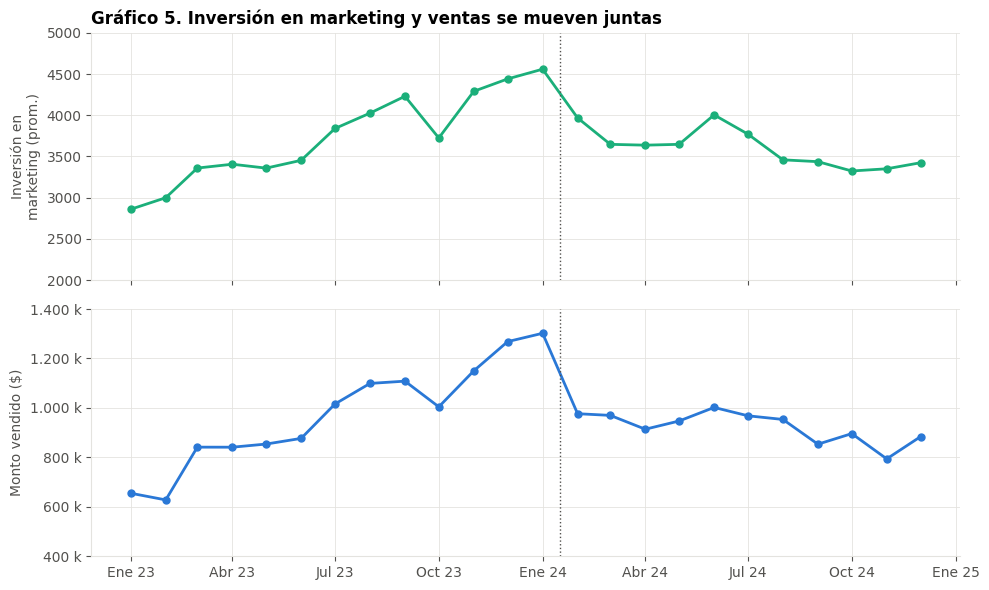

In [17]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
a1.plot(mensual.index, mensual['inversion_mkt'], color=C[2], lw=2, marker='o', ms=5)
a1.set_ylabel('Inversión en\nmarketing (prom.)'); a1.set_ylim(2000, 5000)
a1.set_title('Gráfico 5. Inversión en marketing y ventas se mueven juntas')
a2.plot(mensual.index, mensual['monto'], color=C[0], lw=2, marker='o', ms=5)
a2.set_ylabel('Monto vendido ($)'); a2.yaxis.set_major_formatter(K); a2.set_ylim(400000, 1400000)
formato_meses(a2); linea_quiebre(a1); linea_quiebre(a2)
plt.tight_layout(); plt.show()

#### 📈 Gráfico 6. Cada punto es un mes

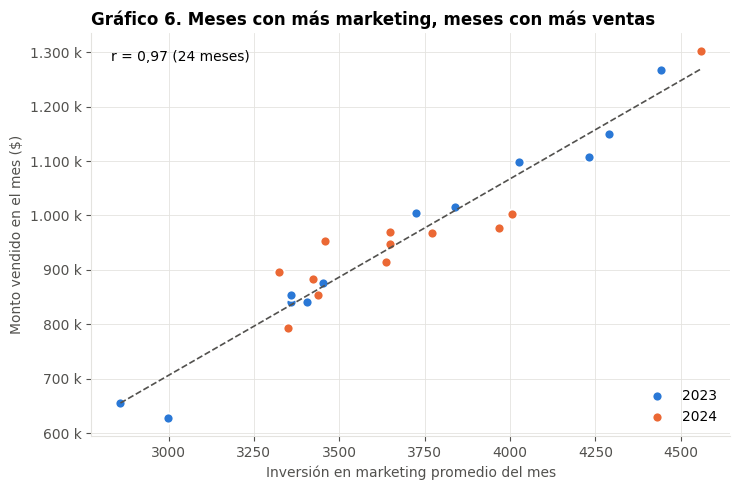

In [18]:
fig, ax = plt.subplots(figsize=(7.5, 5))
es_2023 = mensual.index.year == 2023
ax.scatter(mensual['inversion_mkt'][es_2023], mensual['monto'][es_2023], s=55, color=C[0], edgecolor='white', lw=1.5, label='2023')
ax.scatter(mensual['inversion_mkt'][~es_2023], mensual['monto'][~es_2023], s=55, color=C[1], edgecolor='white', lw=1.5, label='2024')
b = np.polyfit(mensual['inversion_mkt'], mensual['monto'], 1)
xs = np.linspace(mensual['inversion_mkt'].min(), mensual['inversion_mkt'].max(), 10)
ax.plot(xs, np.polyval(b, xs), color=INK2, lw=1.2, ls='--')
ax.text(0.03, 0.93, f'r = {r_mensual:.2f} (24 meses)'.replace('.', ','), transform=ax.transAxes, fontsize=10)
ax.yaxis.set_major_formatter(K)
ax.set_xlabel('Inversión en marketing promedio del mes'); ax.set_ylabel('Monto vendido en el mes ($)')
ax.set_title('Gráfico 6. Meses con más marketing, meses con más ventas'); ax.legend(frameon=False, loc='lower right')
plt.tight_layout(); plt.show()

**Lectura:** venta por venta la correlación es moderada (0,29), pero mes a mes es muy alta (0,97). El marketing no agranda cada compra individual, pero los meses con más inversión son los meses con más ventas. ⚠️ Correlación no implica causalidad.

### 2.5 Productos, ciudades y edades

In [19]:
por_producto = datalatte.pivot_table(index='Producto', columns='Año', values='Monto', aggfunc='sum')
por_producto['variacion_%'] = ((por_producto[2024] / por_producto[2023] - 1) * 100).round(1)
por_producto['peso_2024_%'] = (por_producto[2024] / por_producto[2024].sum() * 100).round(1)
print('Por producto:'); display(por_producto.round(0))

por_ciudad = datalatte.pivot_table(index='Ciudad', columns='Año', values='Monto', aggfunc='sum')
por_ciudad['variacion_%'] = ((por_ciudad[2024] / por_ciudad[2023] - 1) * 100).round(1)
print('Por ciudad:'); display(por_ciudad.round(0))

datalatte['Grupo edad'] = pd.cut(datalatte['Edad'], [17, 30, 45, 60, 120], labels=['18-30', '31-45', '46-60', '61+'])
print('Ticket promedio por grupo de edad:')
display(datalatte.pivot_table(index='Grupo edad', columns='Año', values='Monto', aggfunc='mean', observed=True).round(0))

Por producto:


Año,2023,2024,variacion_%,peso_2024_%
Producto,,,,
Accesorios de Café,2821165.0,2749007.0,-3.0,24.0
Café Molido,2739535.0,2804440.0,2.0,24.0
Combos Especiales,2861859.0,2919873.0,2.0,26.0
Granos de Café,2803733.0,2875384.0,3.0,25.0
Producto no registrado,116565.0,112380.0,-4.0,1.0


Por ciudad:


Año,2023,2024,variacion_%
Ciudad,,,
Canelones,2838824.0,2907431.0,2.0
Colonia,2883754.0,2981452.0,3.0
Maldonado,2783536.0,2787805.0,0.0
Montevideo,2836743.0,2784395.0,-2.0


Ticket promedio por grupo de edad:


Año,2023,2024
Grupo edad,,
18-30,565.0,569.0
31-45,573.0,574.0
46-60,568.0,576.0
61+,575.0,566.0


#### 📈 Gráfico 7. Productos por semestre

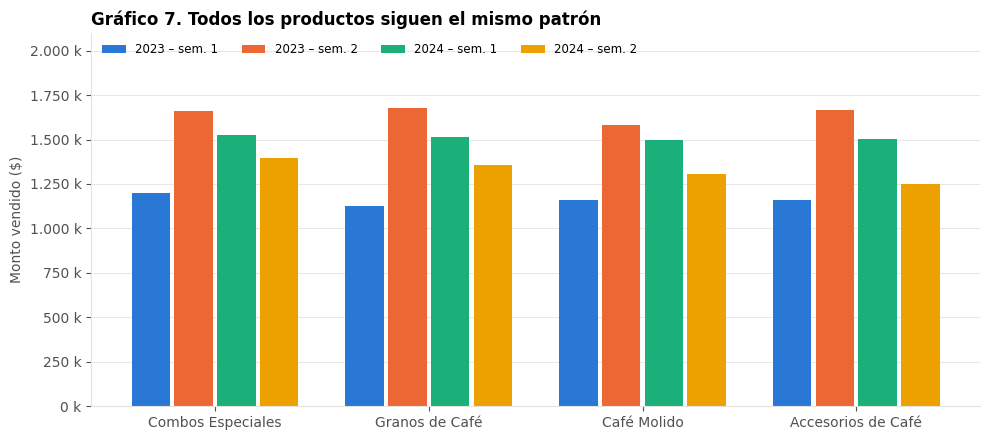

In [20]:
prods = ['Combos Especiales', 'Granos de Café', 'Café Molido', 'Accesorios de Café']   # sin 'Producto no registrado' (1 %)
sems = ['2023-S1', '2023-S2', '2024-S1', '2024-S2']
prod_sem = datalatte.pivot_table(index='Producto', columns='Semestre', values='Monto', aggfunc='sum')
fig, ax = plt.subplots(figsize=(10, 4.5)); w = 0.2; x = np.arange(len(prods))
for i, s in enumerate(sems):
    ax.bar(x + (i - 1.5) * w, prod_sem.loc[prods, s], width=w - 0.02, color=C[i], label=s.replace('-S', ' – sem. '))
ax.set_xticks(x); ax.set_xticklabels(prods); ax.yaxis.set_major_formatter(K); ax.set_ylabel('Monto vendido ($)')
ax.grid(axis='x', visible=False); ax.set_ylim(0, 2100000)
ax.set_title('Gráfico 7. Todos los productos siguen el mismo patrón')
ax.legend(frameon=False, ncol=4, fontsize=8.5, loc='upper left')
plt.tight_layout(); plt.show()

**Lectura:** productos, ciudades y edades se mueven todos igual: la causa es general, no de un segmento.

### 2.6 Estimación: ¿cuánto se perdió en Online Global?
Si Online Global hubiera mantenido el ticket de enero de 2024 con la misma cantidad de ventas:

In [21]:
post = online_global[online_global['Fecha'] >= '2024-02-01']
perdida = len(post) * (og_ene - post['Monto'].mean())
crec_alt = (anual.loc[2024, 'monto'] + perdida) / anual.loc[2023, 'monto'] - 1
print('Ventas de Online Global desde febrero 2024:', len(post))
print('Facturación "perdida": ${:,.0f}'.format(perdida).replace(',', '.'))
print('Crecimiento 2024 que habría tenido la empresa: {:.1%} (en lugar de {:.1%})'.format(
    crec_alt, anual.loc[2024, 'monto'] / anual.loc[2023, 'monto'] - 1))

Ventas de Online Global desde febrero 2024: 4455
Facturación "perdida": $1.550.542
Crecimiento 2024 que habría tenido la empresa: 14.7% (en lugar de 1.0%)


### 2.7 Controles de robustez
¿Las conclusiones dependen de la imputación del Módulo III (montos vacíos rellenados con la mediana)?

In [22]:
mediana = datalatte['Monto'].median()
datalatte['imputado'] = datalatte['Monto'] == mediana
print('Montos imputados con la mediana (${:.2f}): {}'.format(mediana, datalatte['imputado'].sum()))
print('\nProporción de imputados por tienda y año:')
display(datalatte.pivot_table(index='Nombre Tienda', columns='Año', values='imputado', aggfunc='mean').round(3))
sin_imp = datalatte[~datalatte['imputado'] & (datalatte['Nombre Tienda'] == 'Online Global')]
print('Ticket Online Global sin imputados (ene/feb/mar 2024):',
      sin_imp.groupby('Mes')['Monto'].mean().loc['2024-01-01':'2024-03-01'].round(0).tolist())
print('Clientes con edad > 100 (dato a revisar):', (datalatte['Edad'] > 100).sum())

Montos imputados con la mediana ($528.68): 1191

Proporción de imputados por tienda y año:


Año,2023,2024
Nombre Tienda,,
Online Global,0.028,0.028
Online Local,0.031,0.030
Tienda Centro,0.033,0.032
Tienda Pocitos,0.029,0.027


Ticket Online Global sin imputados (ene/feb/mar 2024): [553.0, 208.0, 214.0]
Clientes con edad > 100 (dato a revisar): 65


## 3. Conclusiones
1. **El estancamiento es un cambio de tendencia:** 2023 creció, 2024 cayó (−32 % entre el pico de enero y diciembre de 2024).
2. **El problema está en el ticket, no en la cantidad:** ~1.660 ventas/mes y 98 % de clientes que se repiten.
3. **Online Global tuvo un quiebre en febrero de 2024:** ticket −61 % de un mes a otro en todos los productos y ciudades; −48 % de facturación en el año (≈ \$1,5 M perdidos; sin eso la empresa habría crecido ~15 %).
4. **En el resto de las tiendas la caída es gradual y acompaña al marketing** (correlación mensual 0,97).
5. **Productos, ciudades y edades no marcan diferencias.**

## 5. Propuestas
1. Investigar qué pasó en Online Global en febrero de 2024 (precios, promoción, moneda o error de datos).
2. Recuperar la inversión en marketing de forma medida, probando primero en una tienda.
3. Trabajar sobre el ticket aprovechando la fidelidad de los clientes (combos, venta complementaria, beneficios) y seguir el ticket por tienda en un tablero mensual.

## 6. Aprendizaje
Un número agregado puede esconder la historia: el total anual decía "estamos igual", pero al abrir los datos por mes, por tienda y separar cantidad y ticket apareció el problema. El nivel de agrupación también cambia la lectura (0,29 venta por venta vs 0,97 mes a mes).

## ✅ Verificación de las cifras del informe
Esta celda recalcula cada número citado en el informe y comprueba que coincida. Si todo está bien, imprime "Todas las cifras verificadas".

In [23]:
def ok(nombre, valor, esperado, tol):
    assert abs(valor - esperado) <= tol, f'{nombre}: {valor} ≠ {esperado}'
    print(f'✔ {nombre}: {valor:,.3f}')

ok('Monto 2023 (M)', anual.loc[2023, 'monto'] / 1e6, 11.34, 0.005)
ok('Monto 2024 (M)', anual.loc[2024, 'monto'] / 1e6, 11.46, 0.005)
ok('Variación anual (%)', (anual.loc[2024, 'monto'] / anual.loc[2023, 'monto'] - 1) * 100, 1.0, 0.05)
ok('Ventas 2023', anual.loc[2023, 'cantidad_ventas'], 19906, 0)
ok('Ventas 2024', anual.loc[2024, 'cantidad_ventas'], 20042, 0)
ok('Clientes 2023', anual.loc[2023, 'clientes'], 4909, 0)
ok('Clientes 2024', anual.loc[2024, 'clientes'], 4901, 0)
ok('Clientes en ambos años', len(ambos), 4811, 0)
ok('Pico enero 2024 (M)', mensual.loc['2024-01-01', 'monto'] / 1e6, 1.30, 0.005)
ok('Dic-24 vs pico (%)', (mensual.loc['2024-12-01', 'monto'] / mensual['monto'].max() - 1) * 100, -32, 0.5)
ok('S2 vs S1 2024 (%)', (semestral['2024-S2'] / semestral['2024-S1'] - 1) * 100, -12.5, 0.05)
ok('Ticket OG enero 2024', og_ene, 553, 0.5)
ok('Ticket OG febrero 2024', og_feb, 217, 0.5)
ok('Variación OG anual (%)', por_tienda.loc['Online Global', 'variacion_%'].item(), -48.2, 0.05)
ok('Correlación mensual', r_mensual, 0.97, 0.005)
ok('Correlación venta por venta', r_venta, 0.29, 0.005)
ok('Pérdida estimada OG (M)', perdida / 1e6, 1.55, 0.005)
ok('Crecimiento alternativo (%)', crec_alt * 100, 14.7, 0.05)
print('\nTodas las cifras verificadas ✅')

✔ Monto 2023 (M): 11.343
✔ Monto 2024 (M): 11.461
✔ Variación anual (%): 1.042
✔ Ventas 2023: 19,906.000
✔ Ventas 2024: 20,042.000
✔ Clientes 2023: 4,909.000
✔ Clientes 2024: 4,901.000
✔ Clientes en ambos años: 4,811.000
✔ Pico enero 2024 (M): 1.302
✔ Dic-24 vs pico (%): -32.101
✔ S2 vs S1 2024 (%): -12.476
✔ Ticket OG enero 2024: 552.607
✔ Ticket OG febrero 2024: 216.527
✔ Variación OG anual (%): -48.200
✔ Correlación mensual: 0.966
✔ Correlación venta por venta: 0.293
✔ Pérdida estimada OG (M): 1.551
✔ Crecimiento alternativo (%): 14.712

Todas las cifras verificadas ✅
